# Error Analysis

In this section we will focus on OOF predictions to identify weak points of model, where it makes mistakes, difficult transactions. Three main questions will be raised:

- **False Negative**: which fraudulent transactions were classified as legitimate (small fraud risk).
- **False Posititve**: which legitimate transactions get high fraud risk.
- **Error Patterns**: do difficult cases share common characteristics, such as `auth_method`, `merchant_risk_score`, or`customer_age`.

## 1. Load Data

We will use the OOF predictions from our original `CatBoost` baseline, where each training row was predicted by a model that did not train on that row.

We will combine these predictions with the original features to investigate difficult transactions.

In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

root = Path("../playground-series-s6e11")

train_df = pd.read_csv(root / "train.csv")
oof_df = pd.read_csv("baseline_artifacts/baseline_oof.csv")

print("Train shape:", train_df.shape)
print("OOF shape:", oof_df.shape)

display(oof_df.head())

Train shape: (699960, 26)
OOF shape: (699960, 4)


,id,is_fraud,fold,oof_pred
0,0,0,1,0.000236
1,1,0,4,0.000531
2,2,0,4,0.008807
3,3,0,4,0.002326
4,4,0,5,0.010569


## 2. Merge OOF Predictions

In [8]:
df = train_df.merge(
    oof_df[["id", "fold", "oof_pred"]],
    on="id"
)

print("Merged shape:", df.shape)

Merged shape: (699960, 28)


## 3. OOF Prediction Distribution

Let's compare the predicted fraud scores for fraudulent and legitimate transactions to see how well the model separates them. We will use overlaid density histogram. This is the way to compare the distribution of two classes.

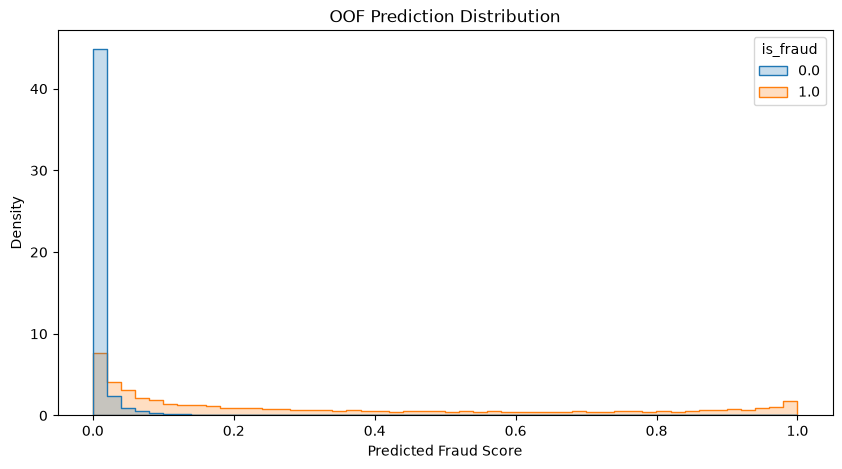

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="oof_pred",
    hue="is_fraud",
    bins=50,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("OOF Prediction Distribution")
plt.xlabel("Predicted Fraud Score")
plt.show()

In [11]:
df.groupby("is_fraud")["oof_pred"].quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).unstack()

,0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99
is_fraud,,,,,,,,,
0.0,0.000014,0.000058,0.000123,0.000414,0.001552,0.005798,0.020595,0.044625,0.185371
1.0,0.001237,0.004965,0.010829,0.044285,0.202214,0.616751,0.905542,0.966782,0.995105


## Findings

Most legitimate transactions receive fraud scores close to zero, while fraudulent transactions are spread across a wider range.

Some fraudulent transactions also receive very low scores, suggesting that the model struggles to identify certain fraud cases.

We will investigate these cases further.

## 4. Difficult Fraud Cases

About **25%** of fraudulent transactions receive scores below ***0.044***.

Let's examine these low-scoring fraud cases and see whether they share any common characteristics.

In [12]:
fraud_df = df[df["is_fraud"] == 1]

threshold = fraud_df["oof_pred"].quantile(0.25)

difficult_fraud = fraud_df[
    fraud_df["oof_pred"] <= threshold
]

print("Threshold:", round(threshold, 4))
print("Difficult fraud cases:", len(difficult_fraud))

Threshold: 0.0443
Difficult fraud cases: 2923


## 5. Difficult vs. Easy Fraud

Let's compare difficult fraud cases with the remaining fraudulent transactions to see what makes them harder to detect.

In [13]:
fraud_df = fraud_df.copy()

fraud_df["group"] = np.where(
    fraud_df["oof_pred"] <= threshold,
    "Difficult",
    "Easy"
)

features = [
    "merchant_risk_score",
    "velocity_score",
    "cvv_retry_count",
    "customer_age"
]

fraud_df.groupby("group")[features].median().T

group,Difficult,Easy
merchant_risk_score,40.2,47.3
velocity_score,22.9,27.9
cvv_retry_count,0.0,1.0
customer_age,57.0,62.0


## Findings

Difficult fraud cases tend to have lower `merchant_risk_score`, `velocity_score`, and `cvv_retry_count`.

These are also among the most important features in our `CatBoost` model, which may explain why these transactions receive lower fraud scores.

***However***, this does not necessarily mean the model is missing useful information.

In [14]:
numeric_features = [
    col for col in train_df.select_dtypes(include="number").columns
    if col not in ["id", "is_fraud"]
]

medians = fraud_df.groupby("group")[numeric_features].median().T

medians["difference"] = (
    medians["Difficult"] - medians["Easy"]
)

medians["relative_difference"] = (
    medians["difference"]
    / medians["Easy"].replace(0, np.nan)
)

display(
    medians.sort_values(
        "relative_difference",
        key=lambda x: x.abs(),
        ascending=False
    )
)

group,Difficult,Easy,difference,relative_difference
cvv_retry_count,0.00,1.000,-1.000,-1.000000
txn_count_last_24h,3.00,4.000,-1.000,-0.250000
velocity_score,22.90,27.900,-5.000,-0.179211
hours_since_last_txn,4.05,3.500,0.550,0.157143
merchant_risk_score,40.20,47.300,-7.100,-0.150106
amount_usd,28.76,31.480,-2.720,-0.086404
customer_age,57.00,62.000,-5.000,-0.080645
account_balance_usd,1398.50,1393.245,5.255,0.003772
distance_from_home_km,10.29,10.310,-0.020,-0.001940
card_age_months,47.00,47.000,0.000,0.000000


## Transactions with Similar Scores

Let's compare fraudulent and legitimate transactions within the same prediction score range (0.01–0.05).

We want to see whether their features differ even when the model assigns them similar scores.

In [15]:
low_score = df[
    df["oof_pred"].between(0.01, 0.05)
]

low_score.groupby("is_fraud")[
    ["merchant_risk_score", "velocity_score",
     "cvv_retry_count", "customer_age"]
].median().T

is_fraud,0.0,1.0
merchant_risk_score,41.8,42.5
velocity_score,24.0,24.2
cvv_retry_count,0.0,0.0
customer_age,58.0,58.0


### Findings

Legitimate transactions with higher fraud scores also tend to show stronger risk signals.

This suggests that the model relies on similar patterns when evaluating both fraudulent and legitimate transactions.

**Next question:** What distinguishes fraudulent transactions from legitimate ones when both appear suspicious?

## 6. Difficult Legitimate Transactions

We have examined fraudulent transactions with low predicted scores. Now let's look at legitimate transactions with the highest fraud scores and compare their characteristics.

In [16]:
normal_df = df[df["is_fraud"] == 0].copy()

threshold_normal = normal_df["oof_pred"].quantile(0.75)

normal_df["group"] = np.where(
    normal_df["oof_pred"] >= threshold_normal,
    "Difficult",
    "Easy"
)

normal_df.groupby("group")[numeric_features].median().T

group,Difficult,Easy
amount_usd,29.70,26.63
hours_since_last_txn,3.89,4.99
txn_count_last_24h,3.00,3.00
distance_from_home_km,10.29,10.21
card_age_months,47.00,47.00
customer_age,58.00,50.00
account_balance_usd,1396.40,1378.68
cvv_retry_count,0.00,0.00
velocity_score,24.10,16.60
time_of_day_hour,12.00,12.00


### Findings

Legitimate transactions with higher fraud scores tend to have stronger risk signals, similar to the patterns we observed in fraudulent transactions.

This suggests that some legitimate transactions may look suspicious to the model.

**Next question:** What distinguishes fraud from legitimate transactions when both receive high fraud scores?

## 7. Fraud vs. Legitimate Transactions with High Scores

Let's compare fraudulent and legitimate transactions with similar high prediction scores.

We want to find out whether there are differences between these groups that the model may not fully capture.

In [17]:
high_score = df[
    df["oof_pred"].between(0.7, 0.9)
]

print(high_score["is_fraud"].value_counts())

high_score.groupby("is_fraud")[numeric_features].median().T

is_fraud
1.0    1240
0.0     328
Name: count, dtype: int64


is_fraud,0.0,1.0
amount_usd,34.145,32.64
hours_since_last_txn,3.460,3.44
txn_count_last_24h,4.000,4.00
distance_from_home_km,10.725,10.42
card_age_months,47.000,47.00
customer_age,63.000,63.00
account_balance_usd,1350.670,1397.06
cvv_retry_count,1.000,1.00
velocity_score,29.650,29.60
time_of_day_hour,11.500,12.00


### Findings

Fraudulent and legitimate transactions with similar high prediction scores have almost identical median feature values.

This suggests that these cases are difficult to distinguish using simple feature comparisons.

We haven't found a clear pattern that could improve ROC-AUC yet, so we will investigate more detailed feature relationships.

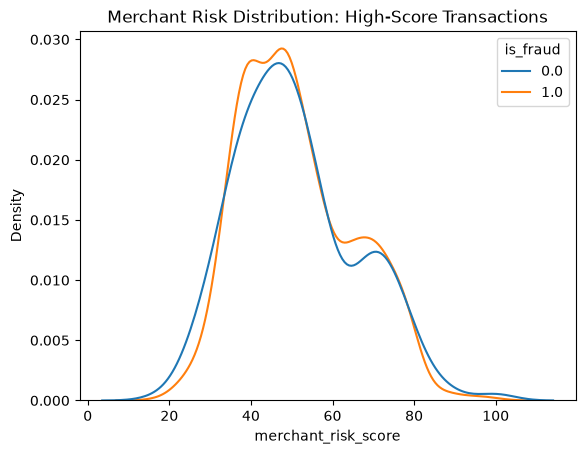

In [18]:
sns.kdeplot(
    data=high_score,
    x="merchant_risk_score",
    hue="is_fraud",
    common_norm=False
)

plt.title("Merchant Risk Distribution: High-Score Transactions")
plt.show()

## Findings

The distributions of `merchant_risk_score` are very similar for fraudulent and legitimate transactions with high prediction scores.

We did not find a clear pattern that could help distinguish these cases.

This suggests that simple comparisons of individual features may not be enough to improve our model.